In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import root_numpy

Welcome to JupyROOT 6.22/02


In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

In [3]:
def getData(branchNames, dfNames, inputFiles, treeName):
    data = root_numpy.root2array(inputFiles, treeName, branches=branchNames)
    return pd.DataFrame(data, columns=dfNames)

In [4]:
def flatten(data, column):
    a = []
    for row in range(0,len(data)):
        a.append(data[row][column])
    return np.concatenate(a)

In [5]:
def getFlattenedData(branchNames, dfNames, inputFiles, treeName):
    data = root_numpy.root2array(inputFiles, treeName, branches=branchNames)
    a = []
    for branchName in branchNames:
        a.append(flatten(data, branchNames.index(branchName)))
    return pd.DataFrame(np.transpose(a), columns=dfNames)

In [16]:
def getRc(dataframe):
    n_ss = dataframe[dataframe.bs==1].shape[0]
    n_os = dataframe[dataframe.bs==-1].shape[0]
    return (n_ss-n_os)/(n_ss+n_os)

In [60]:
observables1 = ['pt','m','q','rg','zg','mg','b','nch']
observabless1 = ['pts','ms','qs','rgs','zgs','mgs','bs','nchs']

In [112]:
df = applyCut(getFlattenedData(observables1, observabless1, '$HOME/output/run12/data0310.root', "ResultTree"),'bs!=0 and rgs>0')

In [113]:
df.eval('absqs=abs(qs)', inplace=True)

In [114]:
df1=df[df.absqs>0.3]

In [115]:
df.shape[0], df1.shape[0]

(134616, 11056)

In [128]:
absqedges=[0,0.05,0.15,0.3,1]
absqcenter=[0.025,0.1,0.225,0.65]

In [129]:
dfs = []
for i in range(0, len(absqcenter)):
    dfs.append(df[np.logical_and(df.absqs>absqedges[i], df.absqs<absqedges[i+1])])

In [130]:
rcs = []
for i in range(0, len(dfs)):
    rcs.append(getRc(dfs[i]))

In [131]:
rcs

[-0.1087072853757358,
 -0.10552953777012411,
 -0.11156272492484864,
 -0.16244573082489147]

Text(0.5, 0, '$Q^{k=2}$')

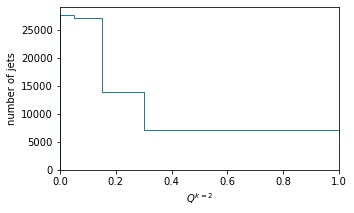

In [134]:
fig=plt.figure(figsize=(5,3))
plt.hist(df['qs'], bins=absqedges, histtype='step')
plt.xlim(0,1)
plt.ylabel('number of jets')
plt.xlabel('$Q^{k=2}$')

(-0.17, -0.1)

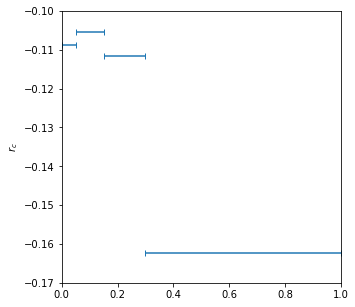

In [135]:
fig=plt.figure(figsize=(5,5))
plt.errorbar(absqcenter, rcs, xerr=np.array(absqcenter)-np.array(absqedges[:-1]), ls='none', capsize=3)
plt.ylabel('$r_c$')
plt.xlim(0,1)
plt.ylim(-0.17,-0.1)

In [136]:
np.mean(df1['nchs'])

3.844880607814761

In [137]:
np.mean(df['nchs'])

4.940586557318595

In [138]:
np.mean(df1['zgs'])

0.19563243397206215

In [139]:
np.mean(df['zgs'])

0.24675635632792245

In [93]:
nchedges=np.arange(2,11)

In [94]:
dfs = []
for i in range(0, len(nchedges)):
    dfs.append(df[df.nchs==nchedges[i]])

In [95]:
rcs = []
for i in range(0, len(dfs)):
    rcs.append(getRc(dfs[i]))

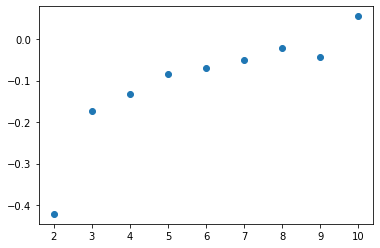

In [96]:
plt.scatter(nchedges, rcs)

(array([8.2087e+04, 2.9134e+04, 1.2339e+04, 6.0390e+03, 3.0250e+03,
        1.3120e+03, 5.2900e+02, 1.4900e+02, 2.0000e+00, 0.0000e+00]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ]),
 <BarContainer object of 10 artists>)

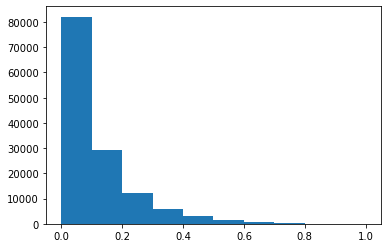

In [108]:
plt.hist(df['absqs'],bins=10, range=(0,1))

In [105]:
df1=df[df.absqs>0.3]

In [97]:
absqedges=[0,0.05,0.1,0.15,0.3,0.8]
absqcenter=[0.025,0.075,0.125,0.225,0.55]

In [98]:
dfs = []
for i in range(0, len(absqcenter)):
    dfs.append(df[np.logical_and(df.absqs>absqedges[i], df.absqs<absqedges[i+1])])

In [99]:
rcs = []
for i in range(0, len(dfs)):
    rcs.append(getRc(dfs[i]))

In [100]:
rcs

[-0.1087072853757358,
 -0.10365218559956993,
 -0.10865912400582503,
 -0.11156272492484864,
 -0.16229419214763888]

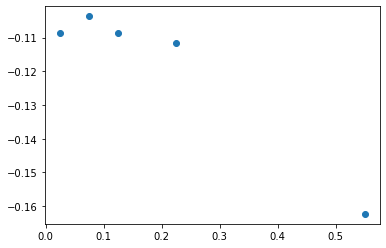

In [101]:
plt.scatter(absqcenter, rcs)

In [32]:
rgedges=np.arange(0,0.45,0.05)
rgcenter=np.arange(0.025,0.425,0.05)

In [33]:
dfs = []
for i in range(0, len(rgcenter)):
    dfs.append(df[np.logical_and(df.rgs>rgedges[i], df.rgs<rgedges[i+1])])

In [34]:
def getRc(dataframe):
    n_ss = dataframe[dataframe.bs==1].shape[0]
    n_os = dataframe[dataframe.bs==-1].shape[0]
    return (n_ss-n_os)/(n_ss+n_os)

In [35]:
rcs = []
for i in range(0, len(dfs)):
    rcs.append(getRc(dfs[i]))

In [36]:
rcs

[-0.12258796821793416,
 -0.13623572256248964,
 -0.14025743453173548,
 -0.12494339052986464,
 -0.12333275593279058,
 -0.10422707157027315,
 -0.09450384543237667,
 -0.0943082675529705]

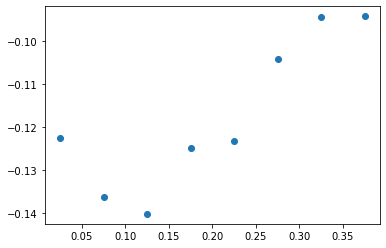

In [37]:
plt.scatter(rgcenter, rcs)

In [38]:
zgedges=np.arange(0.1,0.55,0.05)
zgcenter=np.arange(0.125,0.525,0.05)

In [39]:
dfs = []
for i in range(0, len(zgcenter)):
    dfs.append(df[np.logical_and(df.zgs>zgedges[i], df.zgs<zgedges[i+1])])

In [40]:
def getRc(dataframe):
    n_ss = dataframe[dataframe.bs==1].shape[0]
    n_os = dataframe[dataframe.bs==-1].shape[0]
    return (n_ss-n_os)/(n_ss+n_os)

In [41]:
rcs = []
for i in range(0, len(dfs)):
    rcs.append(getRc(dfs[i]))

In [42]:
rcs

[-0.11864310954063605,
 -0.11715343480049363,
 -0.10956731032219244,
 -0.10690646520024069,
 -0.10610718737017033,
 -0.1077182465342825,
 -0.10786563738785729,
 -0.11025968497232864]

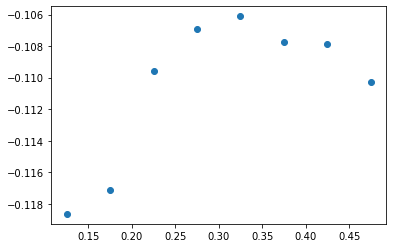

In [43]:
plt.scatter(zgcenter, rcs)

In [54]:
medges=np.arange(1,6)
mcenter=np.arange(1.5,5.5)

In [55]:
dfs = []
for i in range(0, len(mcenter)):
    dfs.append(df[np.logical_and(df.ms>medges[i], df.ms<medges[i+1])])

In [56]:
def getRc(dataframe):
    n_ss = dataframe[dataframe.bs==1].shape[0]
    n_os = dataframe[dataframe.bs==-1].shape[0]
    return (n_ss-n_os)/(n_ss+n_os)

In [57]:
rcs = []
for i in range(0, len(dfs)):
    rcs.append(getRc(dfs[i]))

In [58]:
rcs

[-0.2065929701462898,
 -0.11823640960809102,
 -0.08453420590720957,
 -0.08197381671701913]

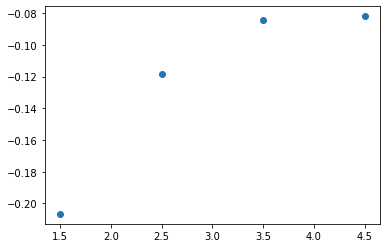

In [59]:
plt.scatter(mcenter, rcs)